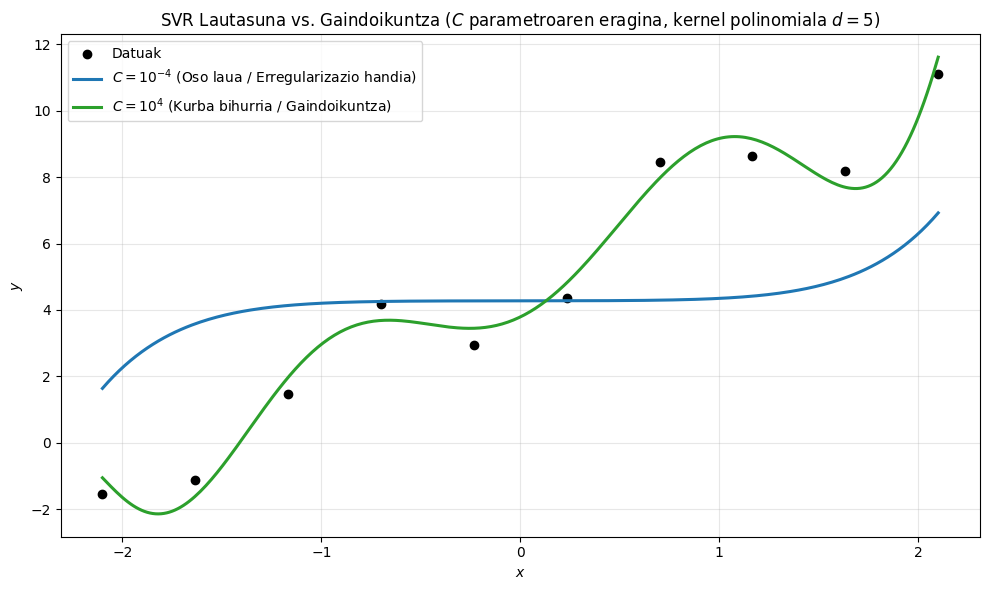

In [51]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVR

# 1. Datu-multzo txikia sortu: y = 3x + 4 + zarata gausiarra
np.random.seed(42)
n_samples = 10
X = np.linspace(-2.1, 2.1, n_samples).reshape(n_samples, 1)
y_true = (3 * X + 4).reshape(n_samples)
y = y_true + np.random.normal(0, 1.5, size=n_samples)

# Irudikapenerako x balioak
X_plot = np.linspace(-2.1, 2.1, 300).reshape(-1, 1)

# 2. Bi SVR eredu sortu kernel polinomialarekin eta C ezberdinekin
C_values = [1e-4, 1e4]
colors = ['#1f77b4', '#2ca02c']
linestyles = ['-', '-']
labels = [
    r'$C = 10^{-4}$ (Oso laua / Erregularizazio handia)',
    r'$C = 10^{4}$ (Kurba bihurria / Gaindoikuntza)'
]

plt.figure(figsize=(10, 6))

# Jatorrizko puntuak
plt.scatter(X, y, color='black', label='Datuak')

# Eredu bakoitza doitu eta marraztu
for C, color, ls, label in zip(C_values, colors, linestyles, labels):
    model = SVR(kernel='poly', degree=8, coef0=1, C=C, epsilon=0.5)
    model.fit(X, y)
    y_pred = model.predict(X_plot)

    plt.plot(X_plot, y_pred, color=color, linestyle=ls, linewidth=2.2, label=label)

# 3. Grafikoaren itxura
plt.title(r'SVR Lautasuna vs. Gaindoikuntza ($C$ parametroaren eragina, kernel polinomiala $d=5$)')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()